# Timeseries — Sisa Umur Pakai (RUL, predictive maintenance)
**Kapan dipakai:** data sensor mesin per siklus, tebak berapa siklus lagi mesin rusak.

**Langkah:** label RUL = siklus maksimum mesin − siklus sekarang, dipotong di `RUL_MAX` (awal
umur mesin dianggap sehat) → fitur bergulir per mesin → split **per mesin** (bukan per baris)
→ model → latih ulang → tebak RUL di siklus terakhir tiap mesin test.

**Data demo:** NASA C-MAPSS FD001. Train = 100 mesin dijalankan sampai rusak. Test = 100 mesin
dipotong di tengah jalan.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/timeseries/rul"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/cmapss_train.csv"
TEST_CSV = f"{DATA_FOLDER}/cmapss_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/cmapss_test_labels.csv"   # hanya ada di data latihan

UNIT_COL = "unit"
CYCLE_COL = "siklus"
# sensor yang berubah selama umur mesin (dipilih dari EDA std di bawah)
SENSOR_COLS = ["s2", "s3", "s4", "s7", "s8", "s9", "s11", "s12", "s13", "s14", "s15", "s17",
               "s20", "s21"]
WINDOW = 10        # panjang rata-rata bergulir per mesin
RUL_MAX = 125
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print(train.shape, test.shape)
print("mesin train:", train[UNIT_COL].nunique(), "| mesin test:", test[UNIT_COL].nunique())
train.head()

(20631, 26) (13096, 26)
mesin train: 100 | mesin test: 100


,unit,siklus,set1,set2,set3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## EDA: sensor yang konstan tidak berguna, umur mesin, contoh tren sensor

s1       0.0000
set3     0.0000
s10      0.0000
s19      0.0000
s18      0.0000
s16      0.0000
s5       0.0000
set2     0.0003
s6       0.0014
set1     0.0022
s15      0.0375
s8       0.0710
s13      0.0719
s21      0.1083
s20      0.1807
s11      0.2671
s2       0.5001
s12      0.7376
s7       0.8851
s17      1.5488
s3       6.1311
s4       9.0006
s14     19.0762
s9      22.0829
dtype: float64
count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: siklus, dtype: float64


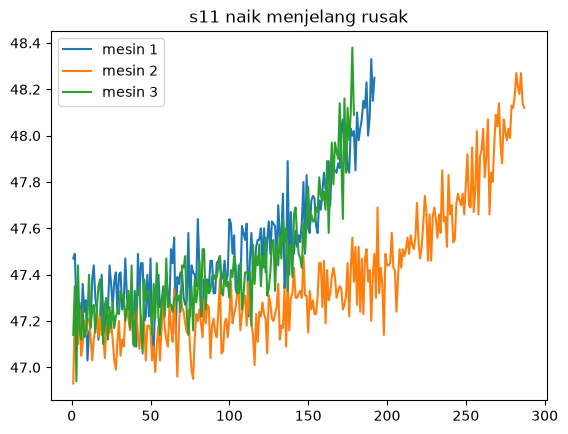

In [4]:
sensor_std = train.drop(columns=[UNIT_COL, CYCLE_COL]).std()
print(sensor_std.sort_values().round(4))
lifetimes = train.groupby(UNIT_COL)[CYCLE_COL].max()
print(lifetimes.describe().round(1))

for unit in [1, 2, 3]:
    machine = train[train[UNIT_COL] == unit]
    plt.plot(machine[CYCLE_COL], machine["s11"], label=f"mesin {unit}")
plt.title("s11 naik menjelang rusak")
plt.legend()
plt.show()

## Label RUL + fitur bergulir per mesin
Per sensor: rata-rata dan simpangan `WINDOW` siklus terakhir, serta selisih dari siklus pertama.

In [5]:
lifetime = train.groupby(UNIT_COL)[CYCLE_COL].transform("max")
train["RUL"] = lifetime - train[CYCLE_COL]
train["RUL"] = train["RUL"].clip(upper=RUL_MAX)


def add_features(table):
    table = table.copy()
    groups = table.groupby(UNIT_COL)[SENSOR_COLS]
    rolling_mean = groups.rolling(WINDOW, min_periods=1).mean()
    rolling_std = groups.rolling(WINDOW, min_periods=2).std()
    first_values = groups.transform("first")
    for column in SENSOR_COLS:
        table[f"{column}_mean"] = rolling_mean[column].droplevel(0)   # buang level unit
        table[f"{column}_std"] = rolling_std[column].droplevel(0)
        table[f"{column}_diff"] = table[column] - first_values[column]
    return table


train = add_features(train)
test = add_features(test)
FEATURES = [CYCLE_COL] + SENSOR_COLS
for column in SENSOR_COLS:
    FEATURES = FEATURES + [f"{column}_mean", f"{column}_std", f"{column}_diff"]
print("jumlah fitur:", len(FEATURES))

jumlah fitur: 57


## Split per mesin (25% mesin jadi validasi)
Simpangan di siklus pertama kosong (NaN) → diisi 0.

In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_index, val_index = next(splitter.split(train, groups=train[UNIT_COL]))
train_part = train.iloc[train_index]
val_part = train.iloc[val_index]
X_train = train_part[FEATURES].fillna(0)
y_train = train_part["RUL"]
X_val = val_part[FEATURES].fillna(0)
y_val = val_part["RUL"]
print("mesin latih:", train_part[UNIT_COL].nunique(), "| validasi:", val_part[UNIT_COL].nunique())

mesin latih: 75 | validasi: 25


## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris LightGBM.

In [7]:
model = LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31, random_state=SEED,
                      verbose=-1)
# model = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED)
# model = ExtraTreesRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED)
# model = HistGradientBoostingRegressor(random_state=SEED)
# model = CatBoostRegressor(iterations=500, random_seed=SEED, verbose=0)
# model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
model.fit(X_train, y_train)

,learning_rate,0.03
,n_estimators,500
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


## Evaluasi: RMSE semua baris validasi + RMSE bila mesin dipotong acak (meniru test)

RMSE semua baris validasi: 12.97
RMSE siklus terakhir (dipotong acak): 16.24


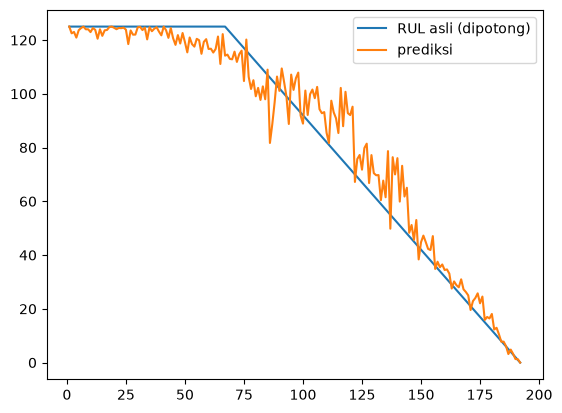

In [8]:
val_predictions = model.predict(X_val)
val_predictions = np.clip(val_predictions, 0, RUL_MAX)
print("RMSE semua baris validasi:", round(root_mean_squared_error(y_val, val_predictions), 2))

rng = np.random.default_rng(SEED)
cut_rows = []
for unit, machine in val_part.groupby(UNIT_COL):
    cut_cycle = rng.integers(31, machine[CYCLE_COL].max())   # mesin dipotong di siklus acak
    cut_rows.append(machine[machine[CYCLE_COL] == cut_cycle])
cut_val = pd.concat(cut_rows)
cut_predictions = model.predict(cut_val[FEATURES].fillna(0))
cut_predictions = np.clip(cut_predictions, 0, RUL_MAX)
cut_rmse = root_mean_squared_error(cut_val["RUL"], cut_predictions)
print("RMSE siklus terakhir (dipotong acak):", round(cut_rmse, 2))

first_unit = val_part[UNIT_COL].iloc[0]
is_first = (val_part[UNIT_COL] == first_unit).to_numpy()
plt.plot(val_part[CYCLE_COL][is_first], y_val[is_first], label="RUL asli (dipotong)")
plt.plot(val_part[CYCLE_COL][is_first], val_predictions[is_first], label="prediksi")
plt.legend()
plt.show()

## Latih ulang di semua mesin train + submission (siklus terakhir tiap mesin test)

In [9]:
final_model = clone(model)
final_model.fit(train[FEATURES].fillna(0), train["RUL"])
last_cycles = test.groupby(UNIT_COL).tail(1)
prediksi = final_model.predict(last_cycles[FEATURES].fillna(0))
prediksi = np.clip(prediksi, 0, RUL_MAX)

submission = pd.DataFrame()
submission["unit"] = last_cycles[UNIT_COL].to_numpy()
submission["RUL"] = prediksi
submission.to_csv("submission.csv", index=False)
submission.head()

,unit,RUL
0,1,123.615136
1,2,122.958961
2,3,52.585436
3,4,86.534550
4,5,87.645028


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)

In [10]:
test_key = pd.read_csv(TEST_KEY_CSV)["RUL"]
print("RMSE test:", round(root_mean_squared_error(test_key, prediksi), 2))
print("RMSE test, kunci dipotong 125:",
      round(root_mean_squared_error(test_key.clip(upper=RUL_MAX), prediksi), 2))

RMSE test: 13.21
RMSE test, kunci dipotong 125: 12.14
